# Forecasting Hourly Bike Rentals
## ANA500 Micro-Project 4
Douglas Bobeck | October 11, 2026

Jupyter Notebook analysis using deep learning regression. This project completes
Acquire, Prepare, Analyze, Report, and Act.

[Repository and submission files](https://github.com/mascon0423/ANA500/tree/main/week4)
| [This Jupyter notebook](https://github.com/mascon0423/ANA500/blob/main/week4/Micro_Project_4.ipynb)

## Results at a glance
The dense neural network was selected using validation data and also had the lowest test error. Its test MAE was 35.61 rentals per hour, RMSE was 55.18, and R-squared was 0.937. Its RMSE was 57.8% below the previous-hour baseline. The basic RNN and LSTM also beat both baselines, but did not outperform the dense network in this comparison. The result supports the predictive hypothesis for these eligible historical hours. A monitored trial on current data is the next step.

## Problem statement and hypothesis
Bike rental activity changes throughout the day. A short-term forecast could help
an operator anticipate system-wide activity. How accurately can the previous 24
hours of recorded rentals and the next hour's calendar information predict rentals
in that next hour?

My hypothesis is that a deep neural network using recent activity and calendar
patterns will reduce forecast error compared with repeating the previous hour or
the same hour yesterday. Commuting schedules and recent activity are possible
reasons for predictable patterns. This study tests prediction, not causation.

Week 3 used the Adult dataset. Week 4 uses hourly bike-sharing data because an RNN
needs a meaningful sequence. Adult rows describe different people and do not form
a time series. Previous weeks remain separate.

## Methods and assumptions
- Compare a dense network, a basic recurrent neural network (RNN), and a long
  short-term memory network (LSTM). The LSTM is also an RNN.
- Use the same eligible hours, 24-hour histories, and calendar inputs for all
  neural models. Each network has at least two hidden layers.
- Train on 2011, select checkpoints and models on January-June 2012, and evaluate
  once on July-December 2012. Choose the model with the lowest validation RMSE.
- Forecast one hour ahead, then use newly observed actual counts for the next
  forecast. This is rolling one-hour forecasting, not a six-month forecast made
  in advance. Model weights remain fixed during testing.
- Assume the prior hour's count is available promptly and the calendar is known.
  Do not use the forecast hour's weather, casual users, or registered users.
- Recorded rentals measure completed activity. They do not reveal unmet demand,
  station inventories, or where bicycles should be moved.

## Acquire
### 1. Load packages and settings
The notebook runs locally in Jupyter with the included CSV. No API key is needed.
PyTorch supplies the neural networks. CPU execution, fixed seeds, and deterministic
operations make the saved run repeatable on this environment. Other library
versions or hardware can still produce different results.

In [1]:
from pathlib import Path
from copy import deepcopy
import hashlib
import json
import platform
import random
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
from torch import nn
from IPython.display import display, Markdown

%matplotlib inline

# All generated analysis files stay inside this notebook's outputs folder.
HERE = Path.cwd()
assert (HERE / "hour.csv").is_file(), "Run from the Week 4 folder."
OUT = HERE / "outputs"
OUT.mkdir(exist_ok=True)
SEED, LOOKBACK, MAX_EPOCHS, PATIENCE = 42, 24, 60, 8
BATCH_SIZE, LEARNING_RATE = 256, 0.001
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
plt.rcParams.update({"figure.figsize": (10, 4.4), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlepad": 14, "savefig.dpi": 160})
COLORS = {"Previous hour": "#6B6B6B", "Same hour yesterday": "#AA6520",
          "Dense network": "#245E83", "Basic RNN": "#77782D", "LSTM": "#985878"}
versions = {"Python": platform.python_version(), "NumPy": np.__version__,
            "Pandas": pd.__version__, "Matplotlib": matplotlib.__version__,
            "PyTorch": torch.__version__}
display(pd.DataFrame(versions.items(), columns=["Package", "Version"]))

,Package,Version
0,Python,3.11.5
1,NumPy,1.26.4
2,Pandas,2.2.2
3,Matplotlib,3.8.4
4,PyTorch,2.6.0


### 2. Check the source file
Source: Fanaee-T, H. (2013). Bike Sharing. UCI Machine Learning Repository.
[Dataset and CC BY 4.0 license](https://doi.org/10.24432/C5W894).
The original source documentation is included as SOURCE_README.txt.

The data describe Capital Bikeshare in Washington, D.C., during 2011-2012.
The downloaded hour.csv and its README contain 17,379 hourly records. The UCI
landing page lists 17,389 instances; this analysis uses the verified CSV count.
The file checksum below identifies the exact input used.

In [2]:
# Check the unchanged input before doing any transformations.
source_hash = hashlib.sha256((HERE / "hour.csv").read_bytes()).hexdigest()
assert source_hash == "e03de4ee4ef4dc376ac6e04bf829673c6269e8eba5c60fa121640fa2f829504f"
raw = pd.read_csv(HERE / "hour.csv")
expected = ["instant", "dteday", "season", "yr", "mnth", "hr", "holiday",
            "weekday", "workingday", "weathersit", "temp", "atemp", "hum",
            "windspeed", "casual", "registered", "cnt"]
assert raw.columns.tolist() == expected and raw.shape == (17379, 17)
assert not raw.isna().any().any()
numeric = raw.drop(columns="dteday").to_numpy()
assert np.isfinite(numeric).all()
assert raw["hr"].between(0, 23).all()
assert raw["workingday"].isin([0, 1]).all()
assert raw["holiday"].isin([0, 1]).all()
assert raw[["cnt", "casual", "registered"]].ge(0).all().all()
assert (raw["cnt"] == raw["casual"] + raw["registered"]).all()
assert (raw["cnt"] % 1 == 0).all()

# Combine date and hour; rows must represent distinct, ordered local clock hours.
times = pd.to_datetime(raw["dteday"], format="%Y-%m-%d")
times += pd.to_timedelta(raw["hr"], unit="h")
assert times.is_unique and times.is_monotonic_increasing
assert (raw["mnth"].to_numpy() == times.dt.month.to_numpy()).all()
assert (raw["yr"].to_numpy() == times.dt.year.to_numpy() - 2011).all()
assert (raw["weekday"].to_numpy() == (times.dt.dayofweek.to_numpy() + 1) % 7).all()
expected_workday = ((times.dt.dayofweek < 5) & raw["holiday"].eq(0)).astype(int)
assert np.array_equal(raw["workingday"], expected_workday)
data = raw.set_index(pd.DatetimeIndex(times, name="time"))
print(f"Source: {len(data):,} recorded hours, {raw.shape[1]} columns.")
print(f"Dates: {data.index.min()} through {data.index.max()}.")
print("SHA-256:", source_hash)
display(data[["cnt", "workingday", "hr"]].head(3))

Source: 17,379 recorded hours, 17 columns.
Dates: 2011-01-01 00:00:00 through 2012-12-31 23:00:00.
SHA-256: e03de4ee4ef4dc376ac6e04bf829673c6269e8eba5c60fa121640fa2f829504f


,cnt,workingday,hr
time,,,
2011-01-01 00:00:00,16,0,0
2011-01-01 01:00:00,40,0,1
2011-01-01 02:00:00,32,0,2


## Prepare
### 3. Preserve gaps and construct 24-hour histories
There are no empty CSV cells, but some clock hours have no row. Missing hours are
unknown, not assumed to be zero. Reindex to the hourly calendar and keep only
windows containing 24 consecutive recorded inputs plus a recorded target hour.
This limits the findings to hours with a complete recent history.

The timestamps have no timezone or UTC offset. The analysis follows the source's
local date/hour labels; daylight-saving transitions are not separately resolved.

In [3]:
# A regular grid makes time gaps visible instead of treating adjacent rows as hours.
grid = pd.date_range(data.index.min(), data.index.max(), freq="h")
hourly = data.reindex(grid)
counts = hourly["cnt"].to_numpy(dtype=float)
missing_hours = int(np.isnan(counts).sum())
windows = np.lib.stride_tricks.sliding_window_view(counts, LOOKBACK + 1)
complete = np.isfinite(windows).all(axis=1)
histories = windows[complete, :LOOKBACK].copy()
targets = windows[complete, LOOKBACK].copy()
target_times = grid[LOOKBACK:][complete]
target_positions = np.arange(LOOKBACK, len(grid))[complete]
excluded_observed = len(data) - len(targets)

# Calendar information is known before the target hour begins.
# Sine/cosine pairs preserve the adjacency of 23:00 and 00:00, and Sunday/Monday.
calendar = np.column_stack([
    np.sin(2 * np.pi * target_times.hour / 24),
    np.cos(2 * np.pi * target_times.hour / 24),
    np.sin(2 * np.pi * target_times.dayofweek / 7),
    np.cos(2 * np.pi * target_times.dayofweek / 7),
    np.sin(2 * np.pi * (target_times.dayofyear - 1) / 365.25),
    np.cos(2 * np.pi * (target_times.dayofyear - 1) / 365.25),
    hourly.loc[target_times, "workingday"].to_numpy(),
]).astype(np.float32)
assert histories.shape == (len(targets), 24) and calendar.shape[1] == 7
assert np.isfinite(calendar).all() and target_times.is_unique
print(f"Calendar hours: {len(grid):,}; missing source hours: {missing_hours:,}.")
print(f"Eligible forecast hours: {len(targets):,}.")
print(f"Recorded targets excluded for insufficient history: {excluded_observed:,}.")

Calendar hours: 17,544; missing source hours: 165.
Eligible forecast hours: 15,657.
Recorded targets excluded for insufficient history: 1,722.


### 4. Split by forecast date and scale with training data
The split uses target timestamps. A validation or test forecast can use actual
counts from earlier hours across a split boundary because those counts are already
known at its forecast time. No future count is an input. Training batches may be
shuffled, but the 24 hours within every sequence keep their order.

In [4]:
train = np.asarray(target_times < "2012-01-01")
valid = np.asarray((target_times >= "2012-01-01") & (target_times < "2012-07-01"))
test = np.asarray(target_times >= "2012-07-01")
assert np.all(train.astype(int) + valid.astype(int) + test.astype(int) == 1)
assert target_times[train].max() < target_times[valid].min()
assert target_times[valid].max() < target_times[test].min()

# Fit count normalization on recorded 2011 counts only, including all training history.
training_counts = hourly.loc[hourly.index < "2012-01-01", "cnt"].dropna()
count_mean, count_sd = float(training_counts.mean()), float(training_counts.std(ddof=0))
assert count_sd > 0
X = torch.tensor((histories - count_mean) / count_sd, dtype=torch.float32).unsqueeze(-1)
C = torch.tensor(calendar, dtype=torch.float32)
y = torch.tensor((targets - count_mean) / count_sd, dtype=torch.float32)
split_rows = []
for name, mask in [("Training", train), ("Validation", valid), ("Test", test)]:
    split_rows.append({"Split": name, "Forecast hours": int(mask.sum()),
                       "First target": str(target_times[mask].min()),
                       "Last target": str(target_times[mask].max())})
split_table = pd.DataFrame(split_rows)
display(split_table)
print(f"Training count mean: {count_mean:.2f}; standard deviation: {count_sd:.2f}.")

,Split,Forecast hours,First target,Last target
0,Training,7279,2011-01-02 00:00:00,2011-12-31 23:00:00
1,Validation,4120,2012-01-01 00:00:00,2012-06-30 23:00:00
2,Test,4258,2012-07-01 00:00:00,2012-12-31 23:00:00


Training count mean: 143.79; standard deviation: 133.79.


### 5. Inspect the training pattern
This figure uses only 2011 training-period observations. Different daily patterns
can motivate calendar inputs without using test results to design the models.

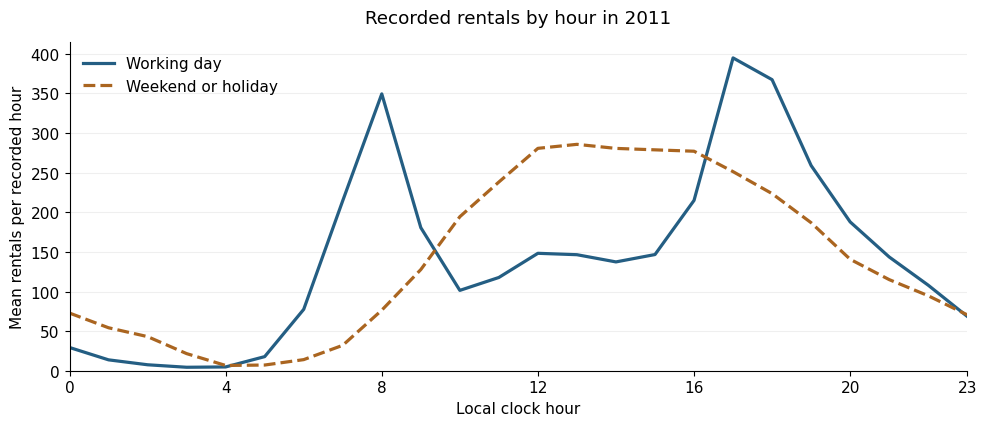

In [5]:
training_pattern = (data.loc[data.index < "2012-01-01"]
                    .groupby(["workingday", "hr"])["cnt"].mean().unstack(0))
fig, ax = plt.subplots()
for flag, label, color, style in [(1, "Working day", "#245E83", "-"),
                                 (0, "Weekend or holiday", "#AA6520", "--")]:
    ax.plot(training_pattern.index, training_pattern[flag], label=label,
            color=color, linestyle=style, linewidth=2.3)
ax.set(title="Recorded rentals by hour in 2011", xlabel="Local clock hour",
       ylabel="Mean rentals per recorded hour", xlim=(0, 23), ylim=(0, None))
ax.set_xticks([0, 4, 8, 12, 16, 20, 23]); ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False); fig.tight_layout()
fig.savefig(OUT / "01_training_pattern.png"); plt.show()

## Analyze
### 6. Define the regression networks and baselines
The dense network reads all 24 lagged counts together. The basic RNN processes
them in order and updates a hidden state. The LSTM adds gates and memory that can
retain useful information across steps. A larger or more complex network is not
guaranteed to forecast better.

The dense network has hidden layers of 64 and 32 units. The RNN and LSTM each
have two recurrent layers of 32 units, followed by a 16-unit hidden layer. All
models combine their history representation with the same seven calendar inputs
and produce one numerical count estimate. Network sizes differ; this compares
these specific configurations, not every possible version of each architecture.

The baselines predict either the previous hour's observed count or the same hour
24 hours earlier. Both are available from the same 24-hour input window.

In [6]:
class ForecastNet(nn.Module):
    """Use the same history and calendar inputs for each neural architecture."""
    def __init__(self, kind):
        super().__init__()
        self.kind = kind
        if kind == "Dense network":
            self.layers = nn.Sequential(nn.Linear(31, 64), nn.ReLU(),
                                        nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1))
        else:
            recurrent = nn.RNN if kind == "Basic RNN" else nn.LSTM
            self.sequence = recurrent(1, 32, num_layers=2, batch_first=True)
            self.layers = nn.Sequential(nn.Linear(39, 16), nn.ReLU(), nn.Linear(16, 1))

    def forward(self, history, known_calendar):
        if self.kind == "Dense network":
            encoded = history.flatten(start_dim=1)
        else:
            sequence_output, _ = self.sequence(history)
            encoded = sequence_output[:, -1, :]
        return self.layers(torch.cat([encoded, known_calendar], dim=1)).squeeze(1)

def predict(model, mask):
    """Return counts in original units, with the prespecified nonnegative floor."""
    model.eval()
    with torch.no_grad():
        estimated = model(X[mask], C[mask]).numpy() * count_sd + count_mean
    return np.maximum(0, estimated)

def metrics(actual, predicted):
    """MAE and RMSE use rental counts; R-squared compares with the actual mean."""
    error = np.asarray(predicted, dtype=float) - np.asarray(actual, dtype=float)
    return {"MAE": float(np.abs(error).mean()),
            "RMSE": float(np.sqrt(np.mean(error ** 2))),
            "R-squared": float(1 - np.sum(error ** 2) /
                               np.sum((actual - actual.mean()) ** 2))}

baseline_predictions = {"Previous hour": histories[:, -1],
                        "Same hour yesterday": histories[:, 0]}
model_names = ["Dense network", "Basic RNN", "LSTM"]
models, history_rows, validation_rows = {}, [], []

### 7. Train and choose checkpoints using validation data
Use Adam at learning rate 0.001 and mean squared error on standardized counts.
Train for at most 60 epochs, with batches of 256 and gradient clipping at 1.0.
Stop after eight epochs without a validation RMSE improvement of at least 0.01
rentals. Restore the lowest validation RMSE checkpoint seen. Apply a zero floor
to predictions before reporting metrics because rental counts cannot be negative.

Only the training set updates weights. Validation chooses epochs and the preferred
model. The test set is not scored until those decisions have been made. The
networks use one fixed initialization seed; repeated-seed and wider tuning studies
would be needed before claiming one architecture is generally superior.

In [7]:
for name, values in baseline_predictions.items():
    validation_rows.append({"Model": name, "Validation RMSE": metrics(targets[valid], values[valid])["RMSE"],
                            "Best epoch": 0, "Epochs run": 0, "Parameters": 0})

train_ids = torch.tensor(np.flatnonzero(train))
for name in model_names:
    # Reset the seed so every model follows a documented initialization and batch order.
    torch.manual_seed(SEED)
    model = ForecastNet(name)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_function = nn.MSELoss()
    generator = torch.Generator().manual_seed(SEED)
    best_rmse, patience_reference, stale = float("inf"), float("inf"), 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        order = train_ids[torch.randperm(len(train_ids), generator=generator)]
        for ids in order.split(BATCH_SIZE):
            optimizer.zero_grad()
            loss = loss_function(model(X[ids], C[ids]), y[ids])
            assert torch.isfinite(loss), "Training produced a nonfinite loss."
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
        train_rmse = metrics(targets[train], predict(model, train))["RMSE"]
        val_rmse = metrics(targets[valid], predict(model, valid))["RMSE"]
        history_rows.append({"Model": name, "Epoch": epoch,
                             "Training RMSE": train_rmse, "Validation RMSE": val_rmse})
        if val_rmse < best_rmse:
            best_rmse, best_epoch = val_rmse, epoch
            best_weights = deepcopy(model.state_dict())
        if val_rmse < patience_reference - 0.01:
            patience_reference, stale = val_rmse, 0
        else:
            stale += 1
        if stale >= PATIENCE:
            break
    model.load_state_dict(best_weights)
    models[name] = model
    validation_rows.append({"Model": name, "Validation RMSE": best_rmse,
                            "Best epoch": best_epoch, "Epochs run": epoch,
                            "Parameters": sum(p.numel() for p in model.parameters())})
    print(f"{name}: best epoch {best_epoch}, validation RMSE {best_rmse:.2f} rentals.")

validation = pd.DataFrame(validation_rows)
selected = validation.loc[validation["Validation RMSE"].idxmin(), "Model"]
selected_neural = validation[validation["Model"].isin(model_names)].sort_values("Validation RMSE").iloc[0]["Model"]
assert selected in model_names + list(baseline_predictions)
print("Preferred model before test evaluation:", selected)
display(validation.round({"Validation RMSE": 2}))

Dense network: best epoch 45, validation RMSE 44.78 rentals.


Basic RNN: best epoch 45, validation RMSE 59.58 rentals.


LSTM: best epoch 33, validation RMSE 64.09 rentals.
Preferred model before test evaluation: Dense network


,Model,Validation RMSE,Best epoch,Epochs run,Parameters
0,Previous hour,113.42,0,0,0
1,Same hour yesterday,123.61,0,0,0
2,Dense network,44.78,45,53,4161
3,Basic RNN,59.58,45,53,3889
4,LSTM,64.09,33,41,13585


### 8. Inspect training and validation error
Solid lines show training error and dashed lines show validation error in rental
counts. A dot marks the saved checkpoint. These are learning curves, not confidence
intervals. Different periods can have different demand levels and error sizes.

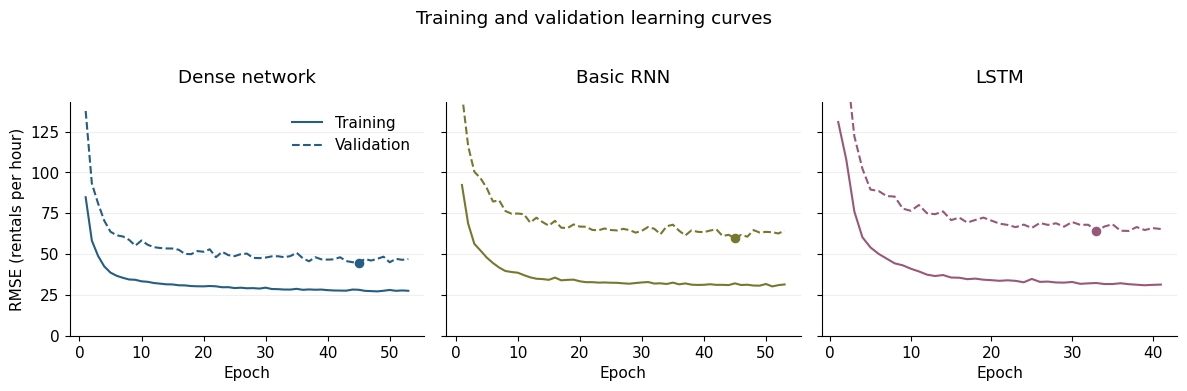

In [8]:
history = pd.DataFrame(history_rows)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, name in zip(axes, model_names):
    h = history[history["Model"] == name]
    best = validation.set_index("Model").loc[name]
    ax.plot(h["Epoch"], h["Training RMSE"], color=COLORS[name], label="Training")
    ax.plot(h["Epoch"], h["Validation RMSE"], color=COLORS[name], linestyle="--", label="Validation")
    ax.scatter([best["Best epoch"]], [best["Validation RMSE"]], color=COLORS[name], s=35)
    ax.set(title=name, xlabel="Epoch", ylim=(0, None)); ax.grid(axis="y", alpha=0.2)
axes[0].set_ylabel("RMSE (rentals per hour)"); axes[0].legend(frameon=False)
fig.suptitle("Training and validation learning curves", y=1.02)
fig.tight_layout(); fig.savefig(OUT / "02_learning_curves.png", bbox_inches="tight"); plt.show()

## Report
### 9. Evaluate the fixed models on the later test period
Report MAE, RMSE, and R-squared on exactly the same eligible July-December 2012
hours. Lower MAE/RMSE is better. R-squared describes performance relative to the
test outcome mean and can be negative. Test results do not change model selection.

,Model,Validation RMSE,MAE,RMSE,R-squared
0,Previous hour,113.420,86.905,130.897,0.647
1,Same hour yesterday,123.615,80.938,134.872,0.625
2,Dense network,44.784,35.608,55.179,0.937
3,Basic RNN,59.579,48.603,79.649,0.869
4,LSTM,64.086,51.296,85.701,0.849


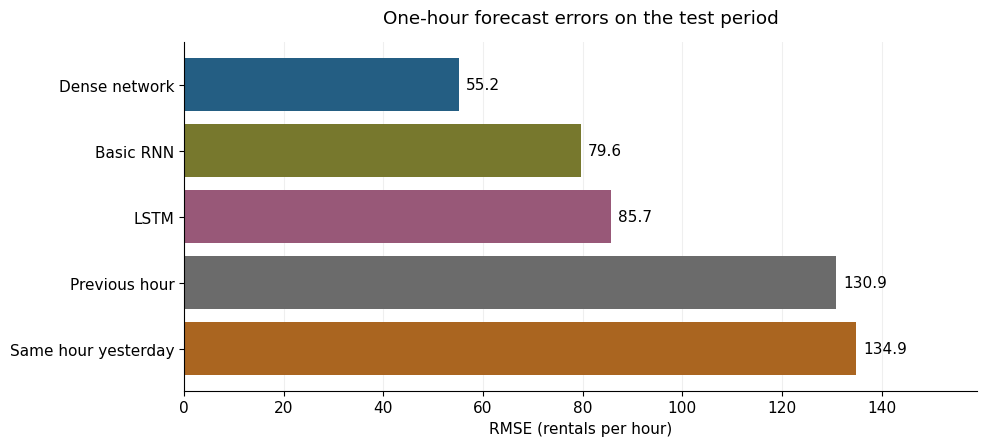

In [9]:
test_predictions = {name: values[test].copy() for name, values in baseline_predictions.items()}
test_predictions.update({name: predict(model, test) for name, model in models.items()})
comparison_rows = []
for name, pred in test_predictions.items():
    comparison_rows.append({"Model": name, **metrics(targets[test], pred)})
comparison = validation.merge(pd.DataFrame(comparison_rows), on="Model", validate="one_to_one")
display(comparison[["Model", "Validation RMSE", "MAE", "RMSE", "R-squared"]].round(3))

fig, ax = plt.subplots(figsize=(10, 4.6))
ordered = comparison.sort_values("RMSE", ascending=False)
bars = ax.barh(ordered["Model"], ordered["RMSE"], color=[COLORS[n] for n in ordered["Model"]])
ax.bar_label(bars, fmt="%.1f", padding=5)
ax.set(title="One-hour forecast errors on the test period", xlabel="RMSE (rentals per hour)",
       xlim=(0, float(ordered["RMSE"].max()) * 1.18))
ax.grid(axis="x", alpha=0.2); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(OUT / "03_test_errors.png"); plt.show()

### 10. Examine the first test week
Show July 1-7, 2012, chosen by date rather than forecast performance. These are
one-hour forecasts using the actual preceding history each time. A missing eligible
forecast stays a gap in the line. The graph does not show a prediction interval.

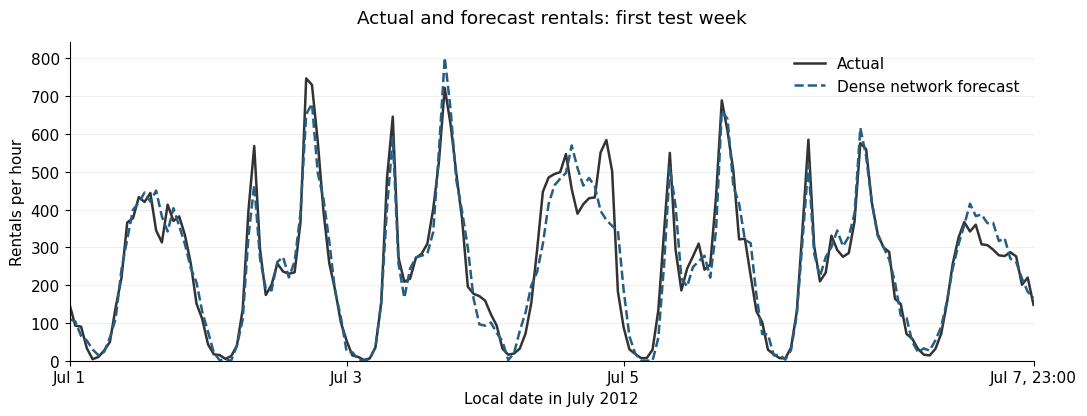

In [10]:
prediction_frame = pd.DataFrame({"time": target_times[test], "Actual": targets[test], **test_predictions})
week_grid = pd.date_range("2012-07-01", "2012-07-07 23:00", freq="h")
first_week = prediction_frame.set_index("time").reindex(week_grid)
fig, ax = plt.subplots(figsize=(11, 4.3))
ax.plot(first_week.index, first_week["Actual"], color="#333333", label="Actual", linewidth=1.8)
ax.plot(first_week.index, first_week[selected], color=COLORS[selected],
        label=selected + " forecast", linestyle="--", linewidth=1.8)
ax.set(title="Actual and forecast rentals: first test week", ylabel="Rentals per hour",
       xlabel="Local date in July 2012", ylim=(0, None))
ax.set_xticks(pd.to_datetime(["2012-07-01", "2012-07-03", "2012-07-05", "2012-07-07 23:00"], format="ISO8601"))
ax.set_xticklabels(["Jul 1", "Jul 3", "Jul 5", "Jul 7, 23:00"])
ax.set_xlim(week_grid.min(), week_grid.max()); ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2); fig.tight_layout()
fig.savefig(OUT / "04_first_test_week.png"); plt.show()

### 11. Check where the selected model makes larger errors
Average error by clock hour can identify times that need closer monitoring. Group
sizes are retained in the output table. These groups use the same test forecasts.

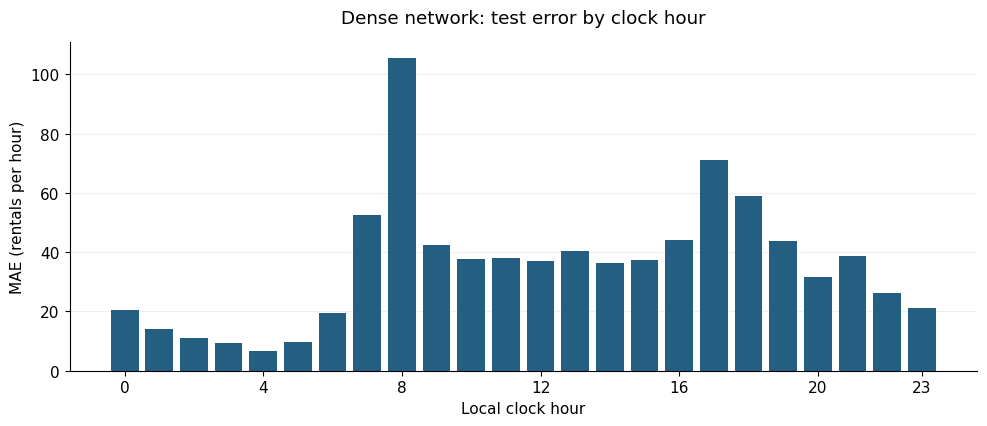

,Hour,n,MAE,Bias
8,8,177,105.48,-90.70
17,17,178,71.10,-27.10
18,18,178,58.94,-9.65
7,7,177,52.48,-25.27


In [11]:
diagnostics = prediction_frame.assign(
    Hour=prediction_frame["time"].dt.hour,
    Absolute_error=np.abs(prediction_frame[selected] - prediction_frame["Actual"]),
    Error=prediction_frame[selected] - prediction_frame["Actual"])
hour_errors = diagnostics.groupby("Hour").agg(n=("Error", "size"),
    MAE=("Absolute_error", "mean"), Bias=("Error", "mean")).reset_index()
fig, ax = plt.subplots()
ax.bar(hour_errors["Hour"], hour_errors["MAE"], color=COLORS[selected], width=0.8)
ax.set(title=selected + ": test error by clock hour", xlabel="Local clock hour",
       ylabel="MAE (rentals per hour)", ylim=(0, None))
ax.set_xticks([0, 4, 8, 12, 16, 20, 23]); ax.grid(axis="y", alpha=0.2); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(OUT / "05_errors_by_hour.png"); plt.show()
display(hour_errors.sort_values("MAE", ascending=False).head(4).round(2))

## Act
### 12. Apply the chosen model
The table below applies the selected model to the first three eligible test hours,
in chronological order. A forecast is a system-wide activity estimate. It is not
a count of bicycles to place at a particular station.

In [12]:
examples = prediction_frame[["time", "Actual", selected]].head(3).copy()
examples.columns = ["Forecast hour", "Actual rentals", "Forecast rentals"]
display(examples.astype({"Forecast rentals": float}).round({"Forecast rentals": 1}))
chosen_scores = comparison.set_index("Model").loc[selected]
baseline_name = validation[validation["Model"].isin(baseline_predictions)].sort_values("Validation RMSE").iloc[0]["Model"]
baseline_rmse = float(comparison.set_index("Model").loc[baseline_name, "RMSE"])
improvement = 100 * (baseline_rmse - chosen_scores["RMSE"]) / baseline_rmse
worst_hour = hour_errors.loc[hour_errors["MAE"].idxmax()]
display(Markdown(
    f"### Decision\n{selected} was selected using validation RMSE. Its test RMSE is "
    f"{chosen_scores['RMSE']:.2f} rentals per hour, compared with {baseline_rmse:.2f} "
    f"for the validation-selected baseline ({baseline_name.lower()}). "
    f"That is a {improvement:.1f}% reduction. Its average absolute miss is "
    f"{chosen_scores['MAE']:.2f} rentals. The highest hourly MAE occurs at "
    f"{int(worst_hour['Hour']):02d}:00 ({worst_hour['MAE']:.2f} rentals; "
    f"n={int(worst_hour['n'])})."))

,Forecast hour,Actual rentals,Forecast rentals
0,2012-07-01 00:00:00,149.0,110.2
1,2012-07-01 01:00:00,93.0,103.9
2,2012-07-01 02:00:00,90.0,65.7


### Decision
Dense network was selected using validation RMSE. Its test RMSE is 55.18 rentals per hour, compared with 130.90 for the validation-selected baseline (previous hour). That is a 57.8% reduction. Its average absolute miss is 35.61 rentals. The highest hourly MAE occurs at 08:00 (105.48 rentals; n=177).

### Practical next step and limits
Use the preferred method as a candidate for a monitored trial on current data.
Record each forecast before the hour starts, compare its weekly error with the
same simple baselines, and agree on an acceptable error with the operator before
allowing forecasts to affect staffing or other operational decisions. Keep a
baseline available and flag forecasts when recent counts are missing.

The hypothesis is supported only if the preselected model improves on both
baselines in the test period. Even then, this single historical split and one
random seed do not prove that the selected architecture is generally best.

This file covers one system in 2011-2012. Eligible windows omit periods with gaps
and may have different activity patterns from excluded hours. Rental activity
changes over time, weather is omitted, and forecasts assume prompt access to
counts. The models provide point estimates, not calibrated prediction intervals.
Current data, multiple seeds, additional time splits, delay testing, and interval
calibration are needed before operational use. Station-level decisions also need
station and inventory data. This completes Step 5, Act, as an evaluated proposal
and application to held-out observations, not a live deployment.

### 13. Verify and save the results
These assertions check timestamps, source preservation, group totals, baseline
formulas, and independently recomputed errors. They fail if the window alignment
or saved comparison is wrong. The notebook retains all code, comments, and outputs.

In [13]:
# Check every window against explicit clock timestamps, not only array shape.
for j, pos in enumerate(target_positions):
    assert np.array_equal(histories[j], counts[pos - 24:pos])
    assert targets[j] == counts[pos]
    assert grid[pos - 1] == target_times[j] - pd.Timedelta(hours=1)
    assert grid[pos - 24] == target_times[j] - pd.Timedelta(hours=24)
assert missing_hours == 165
assert len(data) == len(targets) + excluded_observed
assert int(hour_errors["n"].sum()) == int(test.sum())
assert np.array_equal(baseline_predictions["Previous hour"], histories[:, -1])
assert np.array_equal(baseline_predictions["Same hour yesterday"], histories[:, 0])
for row in comparison.to_dict("records"):
    actual, pred = targets[test], test_predictions[row["Model"]]
    assert len(pred) == int(test.sum()) and np.isfinite(pred).all() and (pred >= 0).all()
    np.testing.assert_allclose(row["MAE"], sum(abs(float(a)-float(p)) for a,p in zip(actual,pred))/len(actual))
    np.testing.assert_allclose(row["RMSE"], (sum((float(a)-float(p))**2 for a,p in zip(actual,pred))/len(actual))**0.5)
for name, model in models.items():
    np.testing.assert_allclose(metrics(targets[valid], predict(model, valid))["RMSE"],
                               validation.set_index("Model").loc[name, "Validation RMSE"])
assert selected == validation.loc[validation["Validation RMSE"].idxmin(), "Model"]
assert hashlib.sha256((HERE / "hour.csv").read_bytes()).hexdigest() == source_hash

comparison.to_csv(OUT / "model_comparison.csv", index=False)
history.to_csv(OUT / "training_history.csv", index=False)
prediction_frame.to_csv(OUT / "test_predictions.csv", index=False)
hour_errors.to_csv(OUT / "errors_by_hour.csv", index=False)
summary = {"source_sha256": source_hash, "versions": versions, "raw_rows": len(data),
    "calendar_hours": len(grid), "missing_hours": missing_hours,
    "eligible_hours": len(targets), "excluded_observed": excluded_observed,
    "splits": split_rows, "training_mean": count_mean, "training_sd": count_sd,
    "lookback": LOOKBACK, "seed": SEED, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
    "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
    "selected_model": selected, "selected_neural": selected_neural,
    "baseline_comparator": baseline_name, "test_rmse_improvement_percent": improvement,
    "hypothesis_supported": bool(all(chosen_scores["RMSE"] < comparison.set_index("Model").loc[n, "RMSE"]
                                     for n in baseline_predictions)),
    "comparison": comparison.to_dict("records"), "hour_errors": hour_errors.to_dict("records"),
    "examples": json.loads(examples.to_json(orient="records", date_format="iso")),
    "training_pattern": [{"hour": int(h), "working": float(r[1]), "nonworking": float(r[0])}
                         for h,r in training_pattern.iterrows()]}
(OUT / "analysis_summary.json").write_text(json.dumps(summary, indent=2))
print("All checks passed. Tables, figures, and the analysis summary were saved.")
print("Hypothesis supported against both test baselines:", summary["hypothesis_supported"])

All checks passed. Tables, figures, and the analysis summary were saved.
Hypothesis supported against both test baselines: True


## Sources
- Fanaee-T, H. (2013). [Bike Sharing](https://doi.org/10.24432/C5W894).
  UCI Machine Learning Repository. CC BY 4.0. Downloaded October 11, 2026.
- Fanaee-T, H., & Gama, J. (2013).
  [Event labeling combining ensemble detectors and background knowledge](https://doi.org/10.1007/s13748-013-0040-3).
  Progress in Artificial Intelligence. Dataset publication specified in the source README.
- PyTorch documentation: [RNN](https://docs.pytorch.org/docs/stable/generated/torch.nn.RNN.html),
  [LSTM](https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html),
  [reproducibility](https://docs.pytorch.org/docs/stable/notes/randomness.html).